# Quantile Regression: A Complete, Production-Ready Guide

### Why Quantile Regression?
In traditional regression (Ordinary Least Squares - OLS), the goal is to model the **conditional mean** of the target variable $Y$ given $X$. However, focusing only on the mean has limitations:
1. **Homoscedasticity Assumption**: OLS assumes constant variance across all levels of $X$. If variance changes (heteroscedasticity), mean-based predictions can be misleading.
2. **Outlier Sensitivity**: OLS is highly sensitive to extreme outliers.
3. **Risk Management / Uncertainty Estimation**: In applications like demand forecasting, financial risk analysis, or interval estimation, you need to understand the bounds of predictions (e.g., "What is the 90th percentile demand?"), not just the average.

**Quantile Regression** models any conditional quantile of the target distribution (e.g., the median ($50\%$, which is robust to outliers), the $10\%$, or the $90\%$ percentile), offering a complete view of the conditional distribution.

## 1. Setup and Synthetic Data Generation

Let's generate synthetic data with **heteroscedastic noise** (variance increasing with $X$) to visually and mathematically demonstrate the power of Quantile Regression.

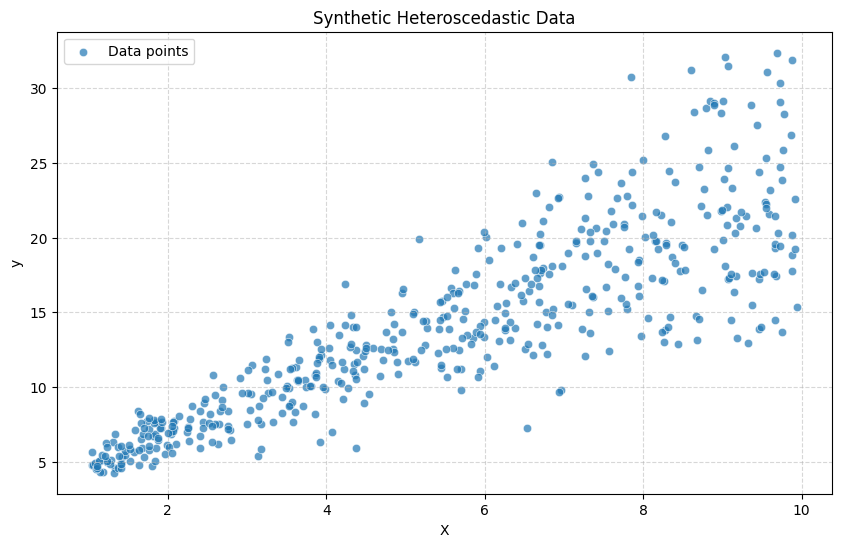

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)

# Generate features
n_samples = 500
X = np.random.uniform(low=1, high=10, size=n_samples)

# Generate heteroscedastic noise (variance increases as X increases)
noise = np.random.normal(loc=0, scale=0.5 * X, size=n_samples)

# Define the target variable (linear relationship + non-constant variance)
y = 3 + 2 * X + noise

# Create a DataFrame
df = pd.DataFrame({'X': X, 'y': y})

# Visualize the relationship
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='X', y='y', alpha=0.7, label='Data points')
plt.title('Synthetic Heteroscedastic Data')
plt.xlabel('X')
plt.ylabel('y')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 2. Linear Quantile Regression with `statsmodels`

For parametric linear modeling, we use `statsmodels.formula.api.quantreg`.

In [2]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Define the quantiles we want to model
quantiles = [0.1, 0.5, 0.9]
models = {}
results = {}

# Fit the quantile models
for q in quantiles:
    model = smf.quantreg('y ~ X', df)
    res = model.fit(q=q)
    results[q] = res
    print(f"--- Quantile: {q} ---")
    print(res.summary().tables[1])
    print("\n")

# Fit an OLS model for comparison
ols_model = smf.ols('y ~ X', df).fit()

--- Quantile: 0.1 ---
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9198      0.365      7.990      0.000       2.202       3.638
X              1.3733      0.061     22.476      0.000       1.253       1.493


--- Quantile: 0.5 ---
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.9038      0.273     10.636      0.000       2.367       3.440
X              2.0186      0.045     45.168      0.000       1.931       2.106


--- Quantile: 0.9 ---
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.4156      0.379      6.368      0.000       1.670       3.161
X              2.8659      0.063     45.392      0.000       

### Plotting the Fits: OLS vs. Quantile Regression
Notice how the slopes of the 10th and 90th percentiles spread out as $X$ increases, capturing the growing uncertainty.

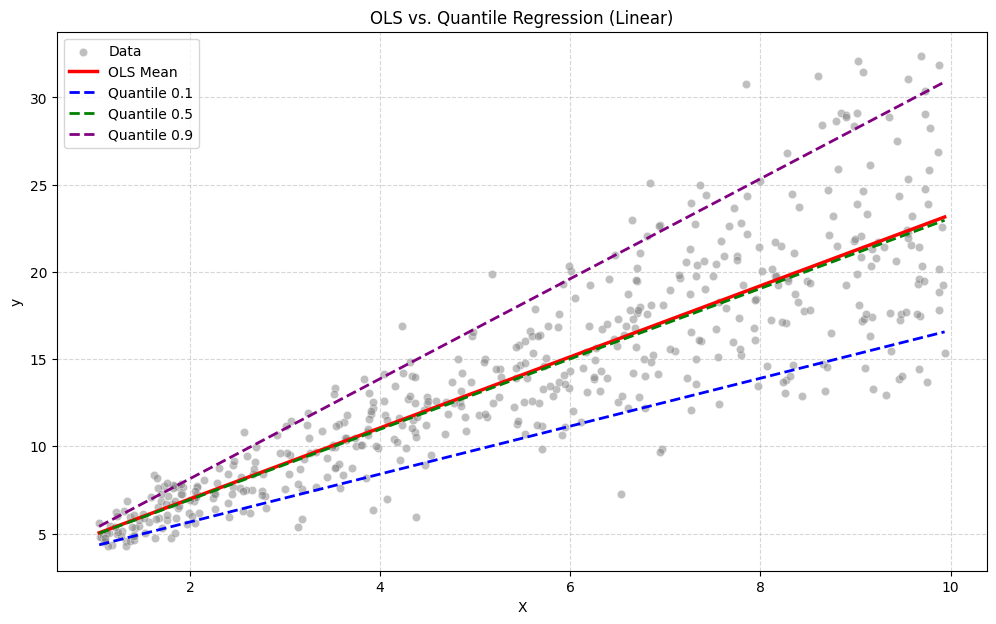

In [3]:
# Prepare prediction grid
x_grid = np.linspace(df['X'].min(), df['X'].max(), 100)
pred_df = pd.DataFrame({'X': x_grid})

plt.figure(figsize=(12, 7))
sns.scatterplot(data=df, x='X', y='y', alpha=0.5, color='gray', label='Data')

# Plot OLS Fit
plt.plot(x_grid, ols_model.predict(pred_df), color='red', label='OLS Mean', linewidth=2.5)

# Plot Quantiles
colors = ['blue', 'green', 'purple']
for q, color in zip(quantiles, colors):
    plt.plot(x_grid, results[q].predict(pred_df), color=color, linestyle='--', label=f'Quantile {q:.1f}', linewidth=2)

plt.title('OLS vs. Quantile Regression (Linear)')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 3. Non-Linear Quantile Regression with LightGBM

In real-world applications, relationships are seldom perfectly linear. Tree-based ensemble models like **LightGBM** support quantile regression out of the box using custom loss functions.

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


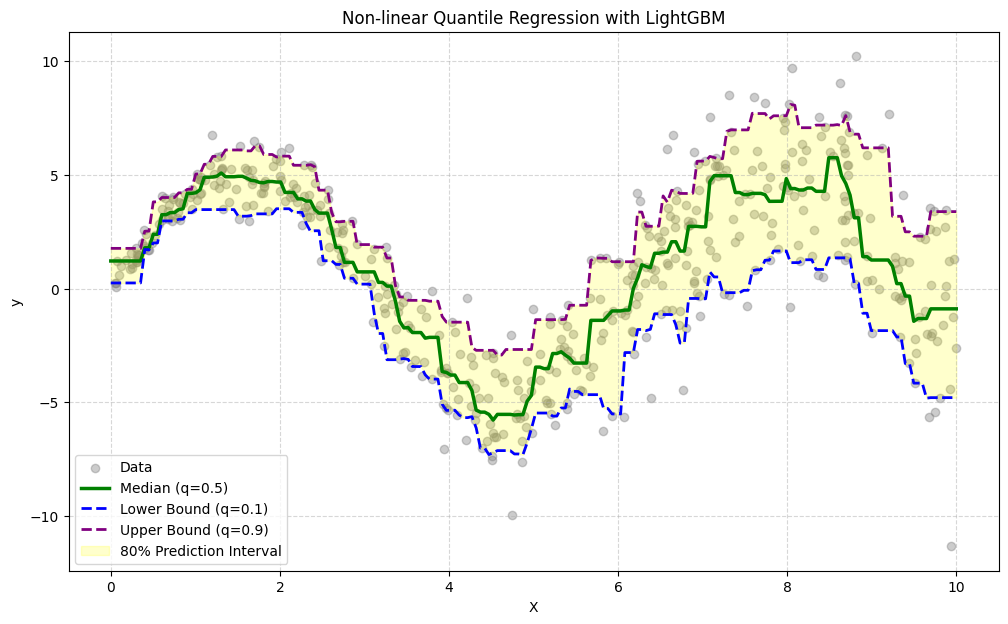

In [4]:
import lightgbm as lgb

# Generate complex non-linear data with heterogeneous noise
X_nl = np.random.uniform(low=0, high=10, size=n_samples)
noise_nl = np.random.normal(loc=0, scale=0.3 * (1 + X_nl), size=n_samples)
y_nl = np.sin(X_nl) * 5 + noise_nl

X_nl_reshaped = X_nl.reshape(-1, 1)

# Train LightGBM regressors for different quantiles
lgb_preds = {}
for q in [0.1, 0.5, 0.9]:
    # Use 'quantile' objective and specify alpha
    reg = lgb.LGBMRegressor(objective='quantile', alpha=q, n_estimators=100, learning_rate=0.05, verbose=-1)
    reg.fit(X_nl_reshaped, y_nl)

    # Predict over a continuous grid
    x_grid_nl = np.linspace(0, 10, 200).reshape(-1, 1)
    lgb_preds[q] = reg.predict(x_grid_nl)

# Plot the non-linear fits
plt.figure(figsize=(12, 7))
plt.scatter(X_nl, y_nl, alpha=0.4, color='gray', label='Data')

plt.plot(np.linspace(0, 10, 200), lgb_preds[0.5], color='green', label='Median (q=0.5)', linewidth=2.5)
plt.plot(np.linspace(0, 10, 200), lgb_preds[0.1], color='blue', linestyle='--', label='Lower Bound (q=0.1)', linewidth=2)
plt.plot(np.linspace(0, 10, 200), lgb_preds[0.9], color='purple', linestyle='--', label='Upper Bound (q=0.9)', linewidth=2)

plt.fill_between(np.linspace(0, 10, 200).flatten(), lgb_preds[0.1], lgb_preds[0.9], color='yellow', alpha=0.2, label='80% Prediction Interval')
plt.title('Non-linear Quantile Regression with LightGBM')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 4. Pinball Loss: Metric for Evaluation

To evaluate quantile predictions, we use **Pinball Loss** (also known as Quantile Loss):
$$
L_q(y, \hat{y}) = \max(q(y - \hat{y}), (q - 1)(y - \hat{y}))
$$
Let's write a python function to compute this metric.

In [5]:
def pinball_loss(y_true, y_pred, quantile):
    """
    Computes the pinball loss metric for a given target and prediction.
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    diff = y_true - y_pred
    loss = np.where(diff >= 0, quantile * diff, (quantile - 1) * diff)
    return np.mean(loss)

# Example Evaluation on training set
for q in [0.1, 0.5, 0.9]:
    # Retrieve predictions for the actual training values using our LightGBM models
    reg = lgb.LGBMRegressor(objective='quantile', alpha=q, n_estimators=100, learning_rate=0.05, verbose=-1)
    reg.fit(X_nl_reshaped, y_nl)
    y_pred_train = reg.predict(X_nl_reshaped)

    loss = pinball_loss(y_nl, y_pred_train, q)
    print(f"Pinball Loss for Quantile {q}: {loss:.4f}")

Pinball Loss for Quantile 0.1: 0.2782
Pinball Loss for Quantile 0.5: 0.6633
Pinball Loss for Quantile 0.9: 0.2631


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


In [6]:
import numpy as np

from sklearn.linear_model import QuantileRegressor
from sklearn.metrics import mean_pinball_loss
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Feature columns: area (square feet), bedrooms
X = np.array([
    [800, 2],
    [900, 2],
    [1000, 2],
    [1100, 2],
    [1200, 3],
    [1300, 3],
    [1400, 3],
    [1500, 3],
    [1600, 4],
    [1700, 4],
    [1800, 4],
    [1900, 4],
], dtype=float)

# Target: house price in lakh rupees
y = np.array([
    28, 31, 34, 36, 39, 42,
    45, 47, 51, 54, 57, 61
], dtype=float)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

model = make_pipeline(
    StandardScaler(),
    QuantileRegressor(
        quantile=0.50,
        alpha=0.0,
        solver="highs"
    )
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Predictions:", y_pred)
print("Actual values:", y_test)

print(
    "Mean pinball loss:",
    mean_pinball_loss(
        y_test,
        y_pred,
        alpha=0.50
    )
)

quantile_model = model.named_steps["quantileregressor"]

print("Coefficients:", quantile_model.coef_)
print("Intercept:", quantile_model.intercept_)

Predictions: [57. 54. 27.]
Actual values: [57. 54. 28.]
Mean pinball loss: 0.16666666666668029
Coefficients: [ 8.91939211e+00 -2.23877347e-14]
Intercept: 42.666666666666664


In [7]:
import numpy as np
from sklearn.linear_model import QuantileRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# X_train, X_test, y_train, and y_test
# should be defined as in the previous example.

quantiles = [0.10, 0.50, 0.90]
models = {}

for q in quantiles:
    model = make_pipeline(
        StandardScaler(),
        QuantileRegressor(
            quantile=q,
            alpha=0.0,
            solver="highs"
        )
    )

    model.fit(X_train, y_train)
    models[q] = model

# Predict for the first test observation
sample = X_test[:1]

for q, model in models.items():
    prediction = model.predict(sample)[0]
    print(f"{q:.0%} quantile prediction: {prediction:.2f} lakh")

10% quantile prediction: 55.33 lakh
50% quantile prediction: 57.00 lakh
90% quantile prediction: 57.67 lakh
